# Bank Marketing Analysis 

**Dataset:** [Bank Marketing Dataset - Kaggle]("https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset")  
**Tool:** Python (pandas, plotnine, seaborn, matplotlib)  


In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import janitor
from plotnine import *
import warnings
import missingno as msno

import importlib
import matplotlib.pyplot as plt
%matplotlib inline
from scripts.profiling import *
from IPython.display import display

warnings.filterwarnings('ignore')

In [2]:
bank_raw = pd.read_csv('../data/raw/bank.csv')


#### Data viewing and interrogation

In [3]:
display(bank_raw)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


**Fix -1 pdays**   

-1 = `never contacted`   

creating 2 columns; `customers who were previously contacted` and `days since last contact`

In [4]:
bank_raw['was_previously_contacted'] = bank_raw['pdays']!= -1
bank_raw['days_since_last_contact'] = bank_raw['pdays'].where(bank_raw['pdays']!= -1)

**Convert yes/no columns into 0/1**   
this is useful for calculating percentages

In [5]:
for col in ['default', 'housing', 'loan', 'deposit']:
    bank_raw[col] = bank_raw[col].map({'yes': 1, 'no': 0})

**Fix month order so it sorts chronologically**

In [6]:
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
bank_raw['month'] = pd.Categorical(bank_raw['month'], categories = month_order, ordered = True)

bank_raw = bank_raw.sort_values('month')

In [7]:
bank_raw['month'].unique().sort_values()

['jan', 'feb', 'mar', 'apr', 'may', ..., 'aug', 'sep', 'oct', 'nov', 'dec']
Length: 12
Categories (12, object): ['jan' < 'feb' < 'mar' < 'apr' ... 'sep' < 'oct' < 'nov' < 'dec']

**Fix edu order so it sorts by skill level not alphabetically**

In [8]:
edu_order = ['unknown', 'primary', 'secondary', 'tertiary']
bank_raw['education'] = pd.Categorical(bank_raw['education'], categories = edu_order, ordered = True)

bank_raw = bank_raw.sort_values('education')

**Create age group**

In [9]:
bank_raw['age_group'] = pd.cut(bank_raw['age'], bins=[17,25,35,45,55,65,100],
                                 labels=['18-25','26-35','36-45','46-55','56-65','66+'])

**Create Campaign bucket group**

In [10]:
bank_raw['campaign_bucket'] = pd.cut(bank_raw['campaign'], bins=[0,1,3,6,100],
                                       labels=['1', '2-3', '4-6', '7+'])

**Create balance group**

In [11]:
bank_raw['balance_tier'] = pd.cut(bank_raw['balance'],
    bins=[-10000, 0, 1000, 5000, 100000],
    labels=['Negative', 'Low (0-1k)', 'Medium (1k-5k)', 'High (5k+)'])

In [12]:
bank_raw.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,campaign,pdays,previous,poutcome,deposit,was_previously_contacted,days_since_last_contact,age_group,campaign_bucket,balance_tier
7091,31,blue-collar,single,unknown,1,17,1,0,cellular,6,...,1,-1,0,unknown,0,False,NaN,26-35,1,Low (0-1k)
10001,22,student,single,unknown,0,1,0,0,telephone,15,...,4,-1,0,unknown,0,False,NaN,18-25,4-6,Low (0-1k)
9888,21,student,single,unknown,0,200,0,0,unknown,1,...,1,-1,0,unknown,0,False,NaN,18-25,1,Low (0-1k)
9853,41,self-employed,single,unknown,0,426,1,0,unknown,19,...,1,-1,0,unknown,0,False,NaN,36-45,1,Low (0-1k)
5619,24,student,single,unknown,0,782,0,0,cellular,4,...,7,91,1,other,0,True,91.0,18-25,7+,Low (0-1k)


In [13]:
bank_raw['days_since_last_contact'].isna().sum()

np.int64(8324)

In [14]:
(bank_raw['was_previously_contacted']==False).sum()

np.int64(8324)

**plot correlation**

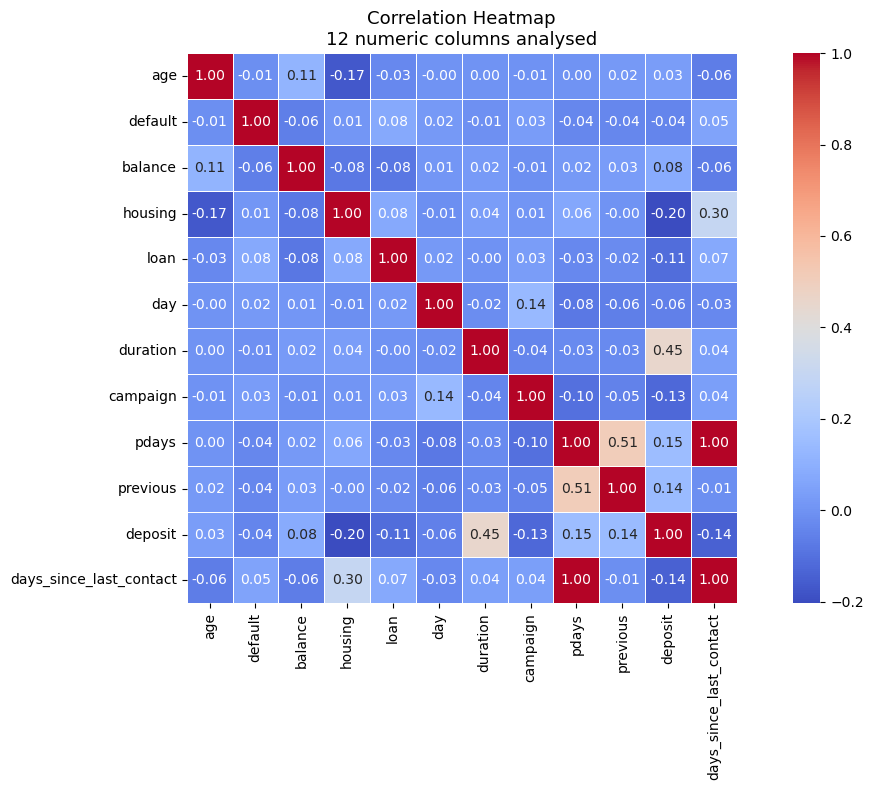

,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,deposit,days_since_last_contact
age,1.000000,-0.011425,0.112300,-0.168700,-0.031418,-0.000762,0.000189,-0.005278,0.002774,0.020169,0.034901,-0.062815
default,-0.011425,1.000000,-0.060954,0.011076,0.076434,0.017342,-0.009760,0.030975,-0.036282,-0.035273,-0.040680,0.054073
balance,0.112300,-0.060954,1.000000,-0.077092,-0.084589,0.010467,0.022436,-0.013894,0.017411,0.030805,0.081129,-0.062961
housing,-0.168700,0.011076,-0.077092,1.000000,0.076761,-0.014770,0.035051,0.006660,0.064497,-0.000840,-0.203888,0.296537
loan,-0.031418,0.076434,-0.084589,0.076761,1.000000,0.017269,-0.001914,0.034722,-0.030416,-0.022668,-0.110580,0.073814
day,-0.000762,0.017342,0.010467,-0.014770,0.017269,1.000000,-0.018511,0.137007,-0.077232,-0.058981,-0.056326,-0.032450
duration,0.000189,-0.009760,0.022436,0.035051,-0.001914,-0.018511,1.000000,-0.041557,-0.027392,-0.026716,0.451919,0.037588
campaign,-0.005278,0.030975,-0.013894,0.006660,0.034722,0.137007,-0.041557,1.000000,-0.102726,-0.049699,-0.128081,0.039973
pdays,0.002774,-0.036282,0.017411,0.064497,-0.030416,-0.077232,-0.027392,-0.102726,1.000000,0.507272,0.151593,1.000000
previous,0.020169,-0.035273,0.030805,-0.000840,-0.022668,-0.058981,-0.026716,-0.049699,0.507272,1.000000,0.139867,-0.012200


In [15]:
plot_correlation(bank_raw, title='Correlation Heatmap', subtitle=None,
                     figsize=(12, 8), cmap='coolwarm')

**Save processed version**

In [ ]:
#bank_raw.to_csv('../data/processed/bank_processed.csv', index=False)

# Save with metadata intact
#bank_raw.to_parquet('../data/processed/bank_metadata.parquet')